chargement des données

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Style des graphiques : une seule couleur pour les données, axes et grille discrets
BLEU, GRIS = "#2a78d6", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": GRIS, "axes.labelcolor": GRIS,
                     "xtick.color": GRIS, "ytick.color": GRIS,
                     "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6})

# Statistiques par film calculées par Hive sur les 33,8 M de notes
stats = pd.read_csv("../results/stats_par_film.tsv", sep="\t")
stats.columns = ["movieId", "nb_notes", "note_moyenne"]   # on enlève le préfixe que Hive peut ajouter

# On ajoute les titres (fichier local, pas envoyé sur GitHub)
movies = pd.read_csv("../data/raw/movies.csv")
stats = stats.merge(movies[["movieId", "title"]], on="movieId", how="left")

print(stats.shape)   # attendu : (83239, 4)
stats.head()

(83239, 4)


,movieId,nb_notes,note_moyenne,title
0,1,76813,3.893508,Toy Story (1995)
1,5,15801,3.076957,Father of the Bride Part II (1995)
2,9,4563,3.003178,Sudden Death (1995)
3,13,2278,3.361721,Balto (1995)
4,17,25248,3.945897,Sense and Sensibility (1995)


combien de notes reçoit un film ?

In [2]:
print(stats["nb_notes"].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]).round(1))
print("Films avec une seule note :", (stats["nb_notes"] == 1).sum())

count     83239.0
mean        406.4
std        2807.0
min           1.0
25%           2.0
50%           5.0
75%          26.0
90%         263.0
95%        1146.0
99%       10069.0
max      122296.0
Name: nb_notes, dtype: float64
Films avec une seule note : 17916


histogramme du nombre de notes par film

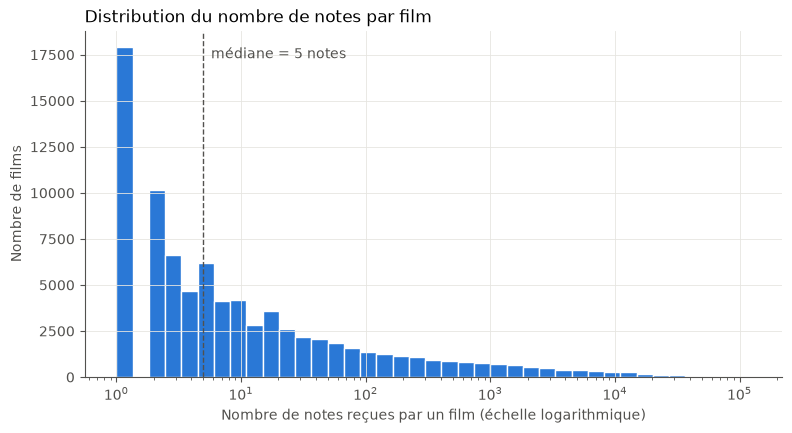

In [3]:
bornes = np.logspace(0, np.log10(stats["nb_notes"].max()), 40)
mediane = stats["nb_notes"].median()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(stats["nb_notes"], bins=bornes, color=BLEU, edgecolor="white", linewidth=1)
ax.set_xscale("log")
ax.axvline(mediane, color=GRIS, linestyle="--", linewidth=1)
ax.text(mediane * 1.15, ax.get_ylim()[1] * 0.92, f"médiane = {mediane:.0f} notes", color=GRIS)
ax.set_xlabel("Nombre de notes reçues par un film (échelle logarithmique)")
ax.set_ylabel("Nombre de films")
ax.set_title("Distribution du nombre de notes par film", loc="left")
fig.savefig("../figures/distribution_nb_notes.png", dpi=150, bbox_inches="tight")
plt.show()

note moyenne en fonction du nombre de notes

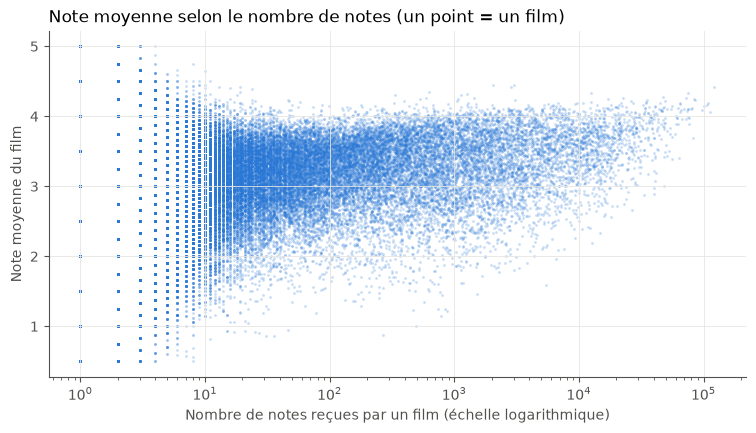

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.scatter(stats["nb_notes"], stats["note_moyenne"], s=4, alpha=0.25, color=BLEU, linewidths=0)
ax.set_xscale("log")
ax.set_xlabel("Nombre de notes reçues par un film (échelle logarithmique)")
ax.set_ylabel("Note moyenne du film")
ax.set_title("Note moyenne selon le nombre de notes (un point = un film)", loc="left")
fig.savefig("../figures/moyenne_vs_nb_notes.png", dpi=150, bbox_inches="tight")
plt.show()

effet de plusieurs seuils

In [5]:
total_notes = stats["nb_notes"].sum()
lignes = []
for seuil in [1, 10, 50, 100, 500, 1000, 5000, 10000]:
    gardes = stats[stats["nb_notes"] >= seuil]
    premier = gardes.sort_values(["note_moyenne", "nb_notes"], ascending=False).iloc[0]
    lignes.append({
        "seuil": seuil,
        "films_gardes": len(gardes),
        "pct_films": round(100 * len(gardes) / len(stats), 1),
        "pct_notes": round(100 * gardes["nb_notes"].sum() / total_notes, 1),
        "film_n1": premier["title"],
        "moyenne_n1": round(premier["note_moyenne"], 3),
        "notes_n1": premier["nb_notes"],
    })
tableau_seuils = pd.DataFrame(lignes)
tableau_seuils.to_csv("../results/effet_du_seuil.csv", index=False)
tableau_seuils

,seuil,films_gardes,pct_films,pct_notes,film_n1,moyenne_n1,notes_n1
0,1,83239,100.0,100.0,The Matrix Revolutions Revisited (2004),5.000,4
1,10,32021,38.5,99.5,Money Heist: The Phenomenon (2020),4.650,10
2,50,16116,19.4,98.5,Planet Earth II (2016),4.452,2041
3,100,12253,14.7,97.7,Planet Earth II (2016),4.452,2041
4,500,6312,7.6,93.6,Planet Earth II (2016),4.452,2041
5,1000,4464,5.4,89.7,Planet Earth II (2016),4.452,2041
6,5000,1559,1.9,70.3,"Shawshank Redemption, The (1994)",4.417,122296
7,10000,840,1.0,55.2,"Shawshank Redemption, The (1994)",4.417,122296


le top 10 change-t-il selon le seuil ?

In [6]:
for seuil in [10, 100, 1000, 5000]:
    top = (stats[stats["nb_notes"] >= seuil]
           .sort_values(["note_moyenne", "nb_notes"], ascending=False)
           .head(10)[["title", "note_moyenne", "nb_notes"]])
    print(f"\n=== Au moins {seuil} notes ===")
    print(top.round(3).to_string(index=False))


=== Au moins 10 notes ===
                                              title  note_moyenne  nb_notes
                 Money Heist: The Phenomenon (2020)         4.650        10
                New York: A Documentary Film (1999)         4.500        11
                             Planet Earth II (2016)         4.452      2041
                                       Evaru (2019)         4.450        10
                                Planet Earth (2006)         4.448      3015
                            Band of Brothers (2001)         4.424      2835
                                     Kantara (2022)         4.423        13
James Acaster: Cold Lasagne Hate Myself 1999 (2020)         4.421        19
                   Shawshank Redemption, The (1994)         4.417    122296
              National Theatre Live: Fleabag (2019)         4.406        16

=== Au moins 100 notes ===
                           title  note_moyenne  nb_notes
          Planet Earth II (2016)         4.452      

moyenne pondérée

In [8]:
# Moyenne pondérée façon IMDb : score = (n * moyenne + m * C) / (n + m)
# C = moyenne de toutes les notes, m = 1000 (même valeur que le seuil)
C = (stats["nb_notes"] * stats["note_moyenne"]).sum() / stats["nb_notes"].sum()
m = 1000
print(f"C = {C:.4f}")

# Seuls les films avec au moins m notes sont classés
eligibles = stats[stats["nb_notes"] >= m].copy()
eligibles["score_pondere"] = (eligibles["nb_notes"] * eligibles["note_moyenne"] + m * C) / (eligibles["nb_notes"] + m)

# Classement : score décroissant, puis le plus noté en cas d'égalité
top10 = eligibles.sort_values(["score_pondere", "nb_notes"], ascending=False).head(10)
top10 = top10[["movieId", "title", "nb_notes", "note_moyenne", "score_pondere"]]
top10.to_csv("../results/top10_reference_pandas.csv", index=False)   # référence pour vérifier Hive et Spark
top10.round(4)

C = 3.5425


,movieId,title,nb_notes,note_moyenne,score_pondere
23442,318,"Shawshank Redemption, The (1994)",122296,4.4168,4.4097
23573,858,"Godfather, The (1972)",75004,4.3266,4.3163
58438,202439,Parasite (2019),12399,4.3299,4.2712
23375,50,"Usual Suspects, The (1995)",72893,4.2679,4.2580
297,1221,"Godfather: Part II, The (1974)",47271,4.2695,4.2544
41984,1203,12 Angry Men (1957),22730,4.2672,4.2366
41820,527,Schindler's List (1993),84232,4.2423,4.2341
42411,2959,Fight Club (1999),86207,4.2360,4.2281
9370,159817,Planet Earth (2006),3015,4.4481,4.2226
42176,2019,Seven Samurai (Shichinin no samurai) (1954),17120,4.2508,4.2117
